# Credit Risk Prediction

## 1. Load the data

The dataset contains information about applicants, their requested loans, and the observed loan outcome. The target column is `loan_status`: `1` means default and `0` means no default.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/raw/credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 2. Exploratory data analysis

Before building a model, I want to understand the shape of the data, the missing values, and how often defaults occur. This also helps identify data-quality issues that need attention later.

### A quick look at the dataset

Check the number of records, column types, and a few example rows before making any changes.

In [3]:
df.shape
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB
None


### Missing values

Missing values are not automatically a reason to drop a row. I will check where they occur and handle them later inside the preprocessing pipeline.

In [4]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

### Target distribution

The target distribution matters because a model can look accurate simply by predicting the majority class. I will keep the original class proportions in the validation and test sets.

In [5]:
df.head()
df['loan_status'].unique()

df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

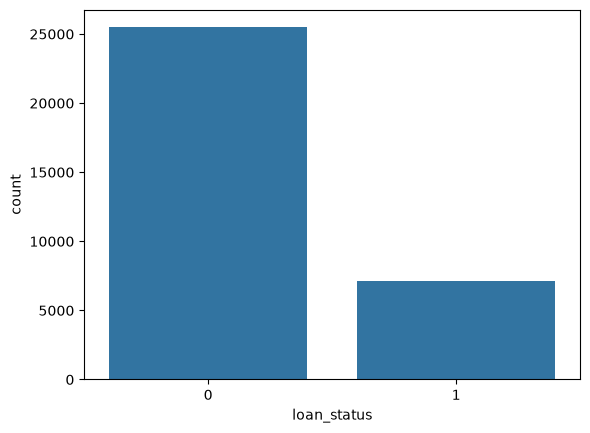

In [6]:
sns.countplot(x='loan_status', data=df)

### Checking unusual values

Boxplots are useful for spotting unusual observations, but an outlier is not necessarily an error. I will use domain checks for clearly invalid values rather than deleting every extreme observation.

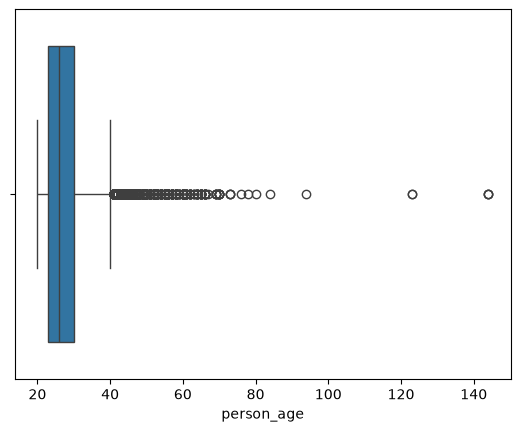

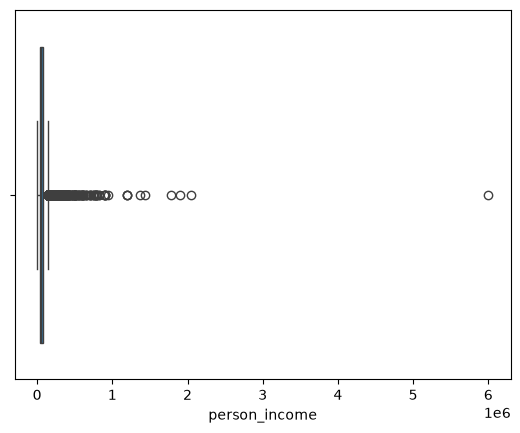

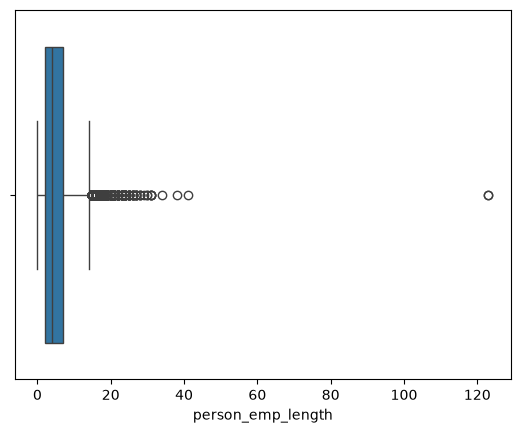

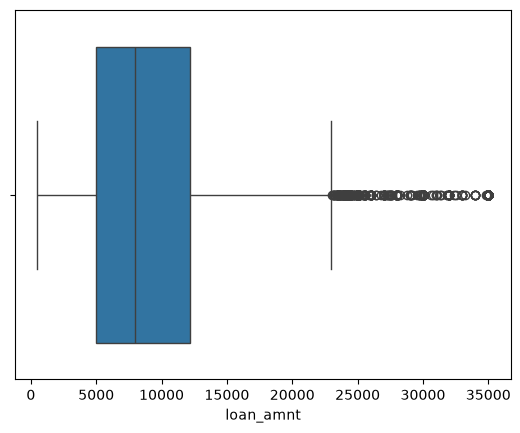

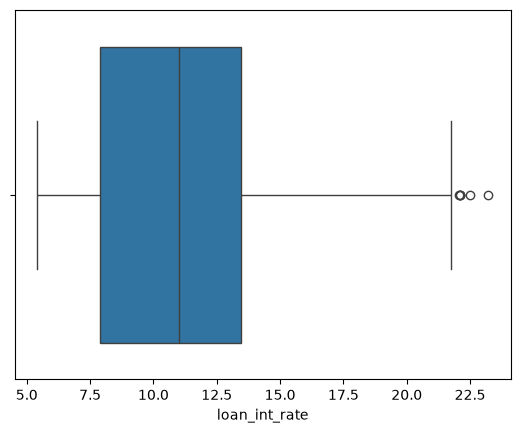

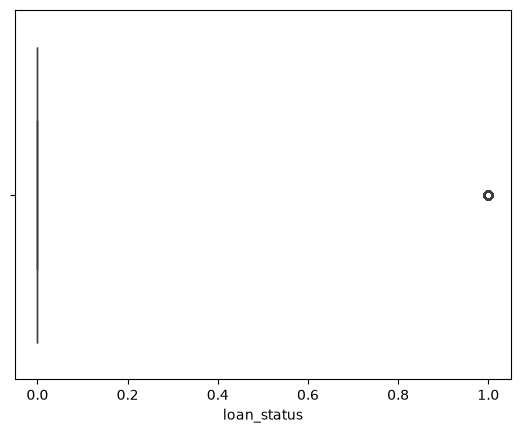

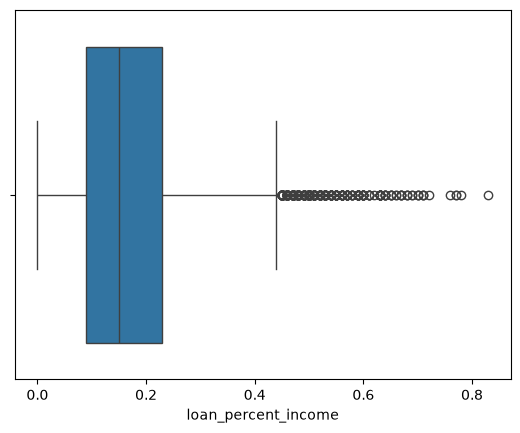

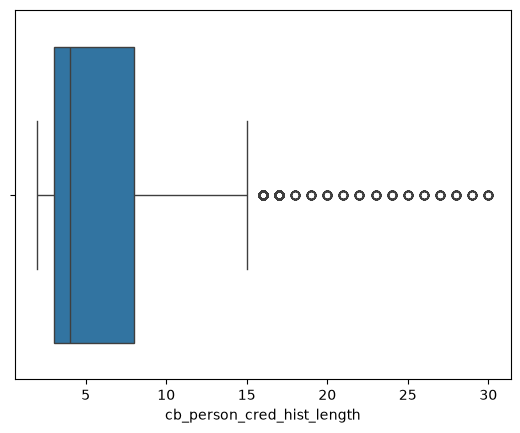

In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns

for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()


In [8]:
(df['person_age'] > 100).sum()

np.int64(5)

In [9]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [10]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


### Correlations

This heatmap gives a quick view of relationships between numeric variables. Correlation is useful for exploration, but it does not by itself tell us whether a feature should be removed.

<Axes: >

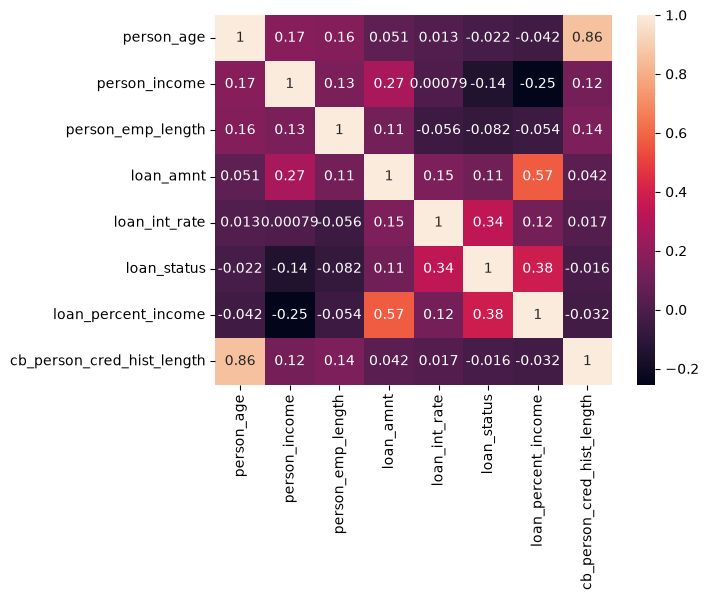

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## 3. Data validation

I remove exact duplicate rows and records that violate straightforward data rules (for example, non-positive income or loan amounts). I keep missing values because the model pipeline will impute them using training data.

In [12]:
df_copy = df.drop_duplicates().copy()
print(f"Rows after removing duplicates: {len(df_copy)}")

valid_rows = (
    df_copy["person_age"].between(18, 100)
    & (
        df_copy["person_emp_length"].isna()
        | (
            df_copy["person_emp_length"].between(0, 60)
            & (df_copy["person_emp_length"] <= df_copy["person_age"])
        )
    )
    & (df_copy["person_income"] > 0)
    & (df_copy["loan_amnt"] > 0)
    & (
        df_copy["loan_int_rate"].isna()
        | df_copy["loan_int_rate"].between(0, 100)
    )
)

print(f"Rows removed by validation rules: {(~valid_rows).sum()}")
df_copy = df_copy.loc[valid_rows].copy()
print(f"Rows retained for modeling: {len(df_copy)}")

Rows after removing duplicates: 32416
Rows removed by validation rules: 7
Rows retained for modeling: 32409


### A note on when the prediction is made

Two columns need a little care: `loan_grade` and `loan_int_rate`. They may be assigned during a lender's underwriting process. If the model is intended to score an application *before* those decisions are made, using them would make the model impractical and could introduce information from a later stage.

For this notebook I treat the task as an underwriting-time assessment, where these fields are assumed to be available. That assumption should be checked against the actual business process before deployment.

In [13]:
feature_availability = pd.DataFrame({
    "feature": ["loan_grade", "loan_int_rate", "loan_percent_income"],
    "question to verify": [
        "Has the lender assigned a grade by the time this score is requested?",
        "Has the proposed interest rate already been calculated?",
        "Are loan amount and applicant income known at this point?"
    ]
})
display(feature_availability)

,feature,question to verify
0,loan_grade,Has the lender assigned a grade by the time th...
1,loan_int_rate,Has the proposed interest rate already been ca...
2,loan_percent_income,Are loan amount and applicant income known at ...


## 4. Features, target and data split

I separate `loan_status` from the applicant information and create three stratified sets. The training set is used to fit models, the validation set is used for model and threshold decisions, and the test set is held back for one final evaluation.

In [14]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status'] #1, 0

In [15]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

In [16]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

## 5. Handling class imbalance

Defaults are less common than non-defaults in this dataset. I calculate the class weight from the training labels only, then pass it to models that support class weighting.

In [17]:
#0 -> no default (majority)
#1 -> default

neg, pos = np.bincount(y_train)
scale_weigths = neg/pos

In [18]:
scale_weigths

np.float64(3.573142050799624)

## 6. Preprocessing

Numeric and categorical columns need different treatment. I use median imputation and scaling for Logistic Regression, while tree-based models use imputation and one-hot encoding without scaling. Keeping these steps inside a pipeline means they are fitted on the training folds, not on the full dataset.

### Preprocessing for Logistic Regression
- Fill missing numeric values.
- Scale numeric values, since this model is sensitive to scale.
- Convert category columns into numbers using one-hot encoding.

In [19]:
#Logistic Regression : impute + SCALE Numeric, impute + One-Hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

### Preprocessing for XGBoost
- Fill missing numeric values.
- No scaling needed here, since tree models don't need it.
- Convert category columns into numbers using one-hot encoding.

In [20]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

## 7. Evaluation helper

I use one function to calculate the main classification metrics so that the models are compared consistently. For metrics that depend on a probability threshold, the threshold is passed explicitly. Ranking metrics use predicted probabilities.

In [21]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, balanced_accuracy_score,
    matthews_corrcoef, brier_score_loss
)

def evaluate_model(model_name, model, X_eval, y_eval, threshold=0.50, show_plot=True):
    # Use probabilities for ranking and probability-quality metrics.
    y_prob = model.predict_proba(X_eval)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0

    metrics = {
        "Model": model_name,
        "Threshold": threshold,
        "ROC-AUC": roc_auc_score(y_eval, y_prob),
        "PR-AUC (AP)": average_precision_score(y_eval, y_prob),
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "F1": f1_score(y_eval, y_pred, zero_division=0),
        "Specificity": specificity,
        "Balanced accuracy": balanced_accuracy_score(y_eval, y_pred),
        "MCC": matthews_corrcoef(y_eval, y_pred),
        "Brier score": brier_score_loss(y_eval, y_prob)
    }

    print(f"{model_name} — threshold: {threshold:.3f}")
    display(pd.DataFrame([metrics]).set_index("Model"))
    print(classification_report(y_eval, y_pred, zero_division=0))

    if show_plot:
        sns.heatmap(
            confusion_matrix(y_eval, y_pred, labels=[0, 1]),
            annot=True, fmt="d", cmap="Blues",
            xticklabels=["No default", "Default"],
            yticklabels=["No default", "Default"]
        )
        plt.title(f"{model_name}: confusion matrix")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.tight_layout()
        plt.show()

    return metrics

## 8. Cross-validation

A single split can give a noisy estimate, so I also use five-fold stratified cross-validation on the training data. The validation set is kept separate for the later model comparison and threshold selection.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate

scoring = {

    "roc_auc": "roc_auc",

    "average_precision": "average_precision",

    "accuracy": "accuracy",

    "precision": "precision",

    "recall": "recall",

    "f1": "f1",

}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [23]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [24]:

! pip install xgboost
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([

    ("preprocessor", preprocessor_xg),

    ("classifier", XGBClassifier(

        n_estimators=300,

        max_depth=5,

        learning_rate=0.1,

        scale_pos_weight=scale_weigths,

        random_state=42,

    )),

])

In [25]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline), ("XGBoost", xgb_cv_pipeline)]:

    cv_results = cross_validate(

        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1

    )

    print(cv_name)

    print(f"ROC-AUC: {cv_results['test_roc_auc'].mean():.3f}")

    print(f"Average precision: {cv_results['test_average_precision'].mean():.3f}")

    print(f"Accuracy: {cv_results['test_accuracy'].mean():.3f}")

    print(f"Precision: {cv_results['test_precision'].mean():.3f}")

    print(f"Recall: {cv_results['test_recall'].mean():.3f}")

    print(f"F1: {cv_results['test_f1'].mean():.3f}")

    print()

Logistic Regression
ROC-AUC: 0.871
Average precision: 0.720
Accuracy: 0.812
Precision: 0.550
Recall: 0.776
F1: 0.644

XGBoost
ROC-AUC: 0.943
Average precision: 0.897
Accuracy: 0.917
Precision: 0.827
Recall: 0.786
F1: 0.806



## 9. Baseline: Logistic Regression

Logistic Regression gives us a useful starting point. It is relatively easy to interpret and provides a reference for judging whether a more complex model is adding value.

In [26]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight= "balanced"))
])
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [27]:
#Evaluate the Logistic Model.

Baseline Logistic Model — threshold: 0.500


,Threshold,ROC-AUC,PR-AUC (AP),Accuracy,Precision,Recall,F1,Specificity,Balanced accuracy,MCC,Brier score
Model,,,,,,,,,,,
Baseline Logistic Model,0.5,0.869118,0.716241,0.8195,0.564315,0.767278,0.650329,0.834123,0.800701,0.543875,0.135629


              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5064
           1       0.56      0.77      0.65      1418

    accuracy                           0.82      6482
   macro avg       0.75      0.80      0.76      6482
weighted avg       0.85      0.82      0.83      6482



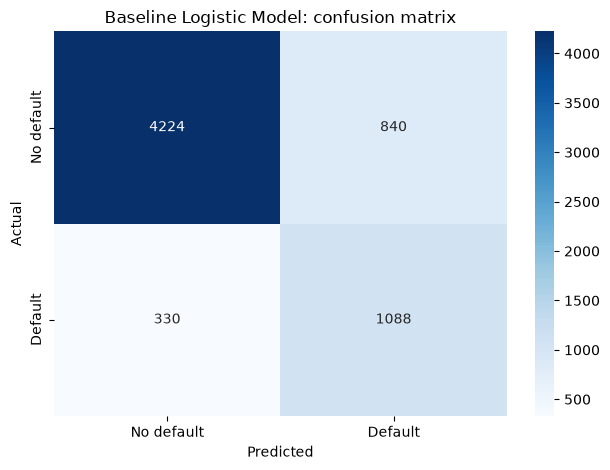

{'Model': 'Baseline Logistic Model',
 'Threshold': 0.5,
 'ROC-AUC': 0.8691176077380197,
 'PR-AUC (AP)': 0.7162414784295993,
 'Accuracy': 0.8195001542733724,
 'Precision': 0.5643153526970954,
 'Recall': 0.767277856135402,
 'F1': 0.6503287507471608,
 'Specificity': np.float64(0.8341232227488151),
 'Balanced accuracy': 0.8007005394421085,
 'MCC': 0.5438750533146537,
 'Brier score': 0.1356291741552993}

In [28]:
evaluate_model("Baseline Logistic Model", baseline_model, X_val, y_val)

## 10. XGBoost tuning

Next I tune XGBoost using cross-validation on the training set. Average precision is the search metric because the default class is the minority class. The validation and test sets are not used during this search.

In [29]:
xg_model = Pipeline([

    ("preprocessor", preprocessor_xg),

    ("classifier", XGBClassifier(

        learning_rate=0.1,

        scale_pos_weight=scale_weigths,

        random_state=42,

    )),

])

In [30]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting

In [31]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....0029187185590>, 'classifier__gamma': <scipy.stats....0029186CDCD60>, 'classifier__learning_rate': <scipy.stats....0029186C7F4D0>, 'classifier__max_depth': <scipy.stats....0029187184F50>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

In [32]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.90


In [33]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8356197935649636),
 'classifier__gamma': np.float64(2.100402725385357),
 'classifier__learning_rate': np.float64(0.06428109553532506),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 5,
 'classifier__n_estimators': 471,
 'classifier__subsample': np.float64(0.92536964212407)}

## 11. Compare models on the validation set

The cross-validation results are useful, but I also want a direct comparison on the same validation rows. This table uses the same metrics and threshold for each model.

In [34]:
lr_val_metrics = evaluate_model(
    "Logistic Regression", baseline_model, X_val, y_val,
    threshold=0.50, show_plot=False
)

Logistic Regression — threshold: 0.500


,Threshold,ROC-AUC,PR-AUC (AP),Accuracy,Precision,Recall,F1,Specificity,Balanced accuracy,MCC,Brier score
Model,,,,,,,,,,,
Logistic Regression,0.5,0.869118,0.716241,0.8195,0.564315,0.767278,0.650329,0.834123,0.800701,0.543875,0.135629


              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5064
           1       0.56      0.77      0.65      1418

    accuracy                           0.82      6482
   macro avg       0.75      0.80      0.76      6482
weighted avg       0.85      0.82      0.83      6482



In [35]:
xgb_val_metrics = evaluate_model(
    "Tuned XGBoost", random_search.best_estimator_, X_val, y_val,
    threshold=0.50, show_plot=False
)

comparison_table = pd.DataFrame([lr_val_metrics, xgb_val_metrics]).set_index("Model")
display(comparison_table.sort_values("PR-AUC (AP)", ascending=False))

Tuned XGBoost — threshold: 0.500


,Threshold,ROC-AUC,PR-AUC (AP),Accuracy,Precision,Recall,F1,Specificity,Balanced accuracy,MCC,Brier score
Model,,,,,,,,,,,
Tuned XGBoost,0.5,0.948667,0.901482,0.917772,0.828508,0.787024,0.807233,0.954384,0.870704,0.755419,0.066524


              precision    recall  f1-score   support

           0       0.94      0.95      0.95      5064
           1       0.83      0.79      0.81      1418

    accuracy                           0.92      6482
   macro avg       0.88      0.87      0.88      6482
weighted avg       0.92      0.92      0.92      6482



,Threshold,ROC-AUC,PR-AUC (AP),Accuracy,Precision,Recall,F1,Specificity,Balanced accuracy,MCC,Brier score
Model,,,,,,,,,,,
Tuned XGBoost,0.5,0.948667,0.901482,0.917772,0.828508,0.787024,0.807233,0.954384,0.870704,0.755419,0.066524
Logistic Regression,0.5,0.869118,0.716241,0.819500,0.564315,0.767278,0.650329,0.834123,0.800701,0.543875,0.135629


## 12. Probability calibration and threshold selection

The model's probability estimates are useful only if they are reasonably calibrated. I fit a sigmoid calibrator using training data, check it on validation data, and choose the classification threshold using validation predictions—not the test set.

Selected validation threshold: 0.633
Validation F1 at selected threshold: 0.823
Calibrated XGBoost (validation) — threshold: 0.633


,Threshold,ROC-AUC,PR-AUC (AP),Accuracy,Precision,Recall,F1,Specificity,Balanced accuracy,MCC,Brier score
Model,,,,,,,,,,,
Calibrated XGBoost (validation),0.633325,0.950451,0.902217,0.93212,0.955307,0.723554,0.823435,0.990521,0.857038,0.793978,0.056351


              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5064
           1       0.96      0.72      0.82      1418

    accuracy                           0.93      6482
   macro avg       0.94      0.86      0.89      6482
weighted avg       0.93      0.93      0.93      6482



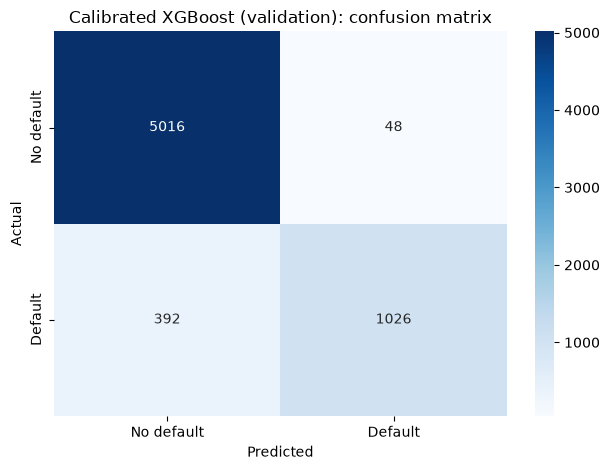

{'Model': 'Calibrated XGBoost (validation)',
 'Threshold': 0.6333248114513086,
 'ROC-AUC': 0.9504507327366271,
 'PR-AUC (AP)': 0.902216816060713,
 'Accuracy': 0.9321197161369947,
 'Precision': 0.9553072625698324,
 'Recall': 0.7235543018335684,
 'F1': 0.8234349919743178,
 'Specificity': np.float64(0.990521327014218),
 'Balanced accuracy': 0.8570378144238933,
 'MCC': 0.7939784092907649,
 'Brier score': 0.056350692687178926}

In [36]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

best_model = random_search.best_estimator_

# The calibrator is fitted with training rows only. Validation rows are used
# afterwards to inspect calibration and choose a decision threshold.
calibrated_model = CalibratedClassifierCV(best_model, method="sigmoid", cv=5)
calibrated_model.fit(X_train, y_train)

val_prob = calibrated_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, val_prob)
f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-9)
)

best_index = int(np.argmax(f1_scores))
best_threshold = float(thresholds[best_index])

print(f"Selected validation threshold: {best_threshold:.3f}")
print(f"Validation F1 at selected threshold: {f1_scores[best_index]:.3f}")

evaluate_model(
    "Calibrated XGBoost (validation)",
    calibrated_model, X_val, y_val, best_threshold
)

## 13. A simple business-cost view

A false negative means a borrower who defaults was classified as lower risk. A false positive means a borrower who does not default was flagged as risky. In practice, the consequences are not equal.

The cost values below are deliberately simple placeholders. They let us see how the threshold changes the trade-off; they are not actual lender losses or an Expected Credit Loss model. I use validation predictions to compare thresholds.

F1-selected threshold: 0.633
Lowest illustrative-cost threshold: 0.1


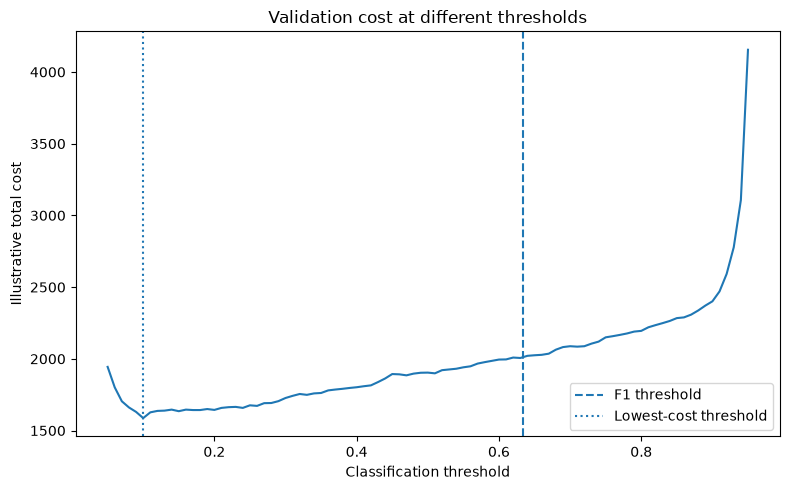

threshold             0.1
false_positives     882.0
false_negatives     141.0
total_cost         1587.0
Name: 5, dtype: float64

In [37]:
# Illustrative cost units only; replace these with assumptions agreed with the business.
cost_fp = 1.0   # cost of flagging a non-default applicant
cost_fn = 5.0   # cost of missing a default

def calculate_business_cost(y_true, probabilities, threshold, cost_fp, cost_fn):
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "false_positives": fp,
        "false_negatives": fn,
        "total_cost": fp * cost_fp + fn * cost_fn
    }

thresholds_to_check = np.linspace(0.05, 0.95, 91)
cost_table = pd.DataFrame([
    calculate_business_cost(y_val, val_prob, t, cost_fp, cost_fn)
    for t in thresholds_to_check
])

cost_threshold = float(cost_table.loc[cost_table["total_cost"].idxmin(), "threshold"])
print("F1-selected threshold:", round(best_threshold, 3))
print("Lowest illustrative-cost threshold:", round(cost_threshold, 3))

plt.figure(figsize=(8, 5))
plt.plot(cost_table["threshold"], cost_table["total_cost"])
plt.axvline(best_threshold, linestyle="--", label="F1 threshold")
plt.axvline(cost_threshold, linestyle=":", label="Lowest-cost threshold")
plt.xlabel("Classification threshold")
plt.ylabel("Illustrative total cost")
plt.title("Validation cost at different thresholds")
plt.legend()
plt.tight_layout()
plt.show()

display(cost_table.loc[cost_table["threshold"].sub(cost_threshold).abs().idxmin()])

### Risk bands for a quick portfolio view

A probability can also be grouped into broad risk bands to make the results easier to discuss. These cutoffs are illustrative, not standard banking policy. The observed default rate in each band is worth checking; a band is only useful if its predicted probabilities are reasonably aligned with outcomes.

,applicants,average_predicted_pd,observed_default_rate,applicant_share
risk_band,,,,
Low risk,4323,0.031314,0.032616,0.666924
Medium risk,772,0.170766,0.196891,0.119099
High risk,1387,0.816303,0.811103,0.213977


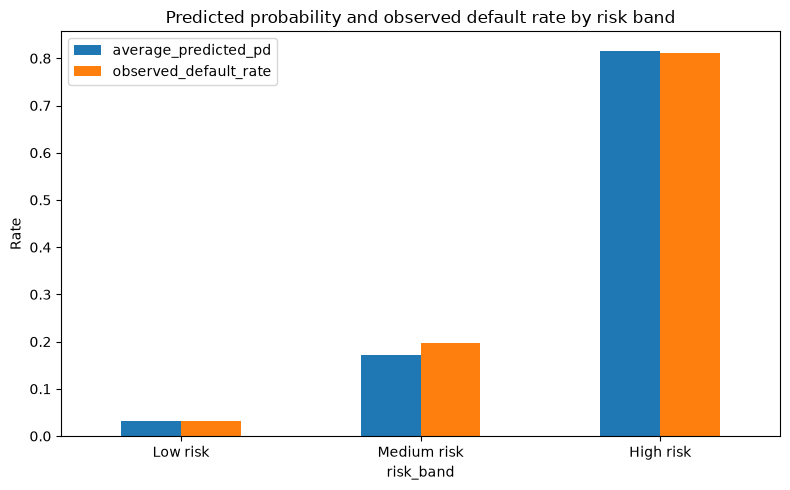

In [38]:
risk_band = pd.cut(
    val_prob,
    bins=[-np.inf, 0.10, 0.30, np.inf],
    labels=["Low risk", "Medium risk", "High risk"]
)

risk_summary = pd.DataFrame({
    "actual_default": y_val.to_numpy(),
    "predicted_pd": val_prob,
    "risk_band": risk_band
}).groupby("risk_band", observed=False).agg(
    applicants=("actual_default", "size"),
    average_predicted_pd=("predicted_pd", "mean"),
    observed_default_rate=("actual_default", "mean")
)

risk_summary["applicant_share"] = risk_summary["applicants"] / len(y_val)
display(risk_summary)

risk_summary[["average_predicted_pd", "observed_default_rate"]].plot(
    kind="bar", figsize=(8, 5)
)
plt.ylabel("Rate")
plt.title("Predicted probability and observed default rate by risk band")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 13. Checking probability calibration

A calibrated model should assign probabilities that broadly agree with observed event rates. I compare the raw and calibrated predictions using a calibration curve and Brier score.

In [39]:
uncalibrated = best_model.predict_proba(X_val)[:, 1]

calibrated = calibrated_model.predict_proba(X_val)[:, 1]

In [40]:
actual_uncal, predicted_uncal = calibration_curve(y_val, uncalibrated, n_bins=10)

In [41]:
actual_cal, predicted_cal = calibration_curve(y_val, calibrated, n_bins=10)

Uncalibrated Brier score: 0.0665
Calibrated Brier score:   0.0564


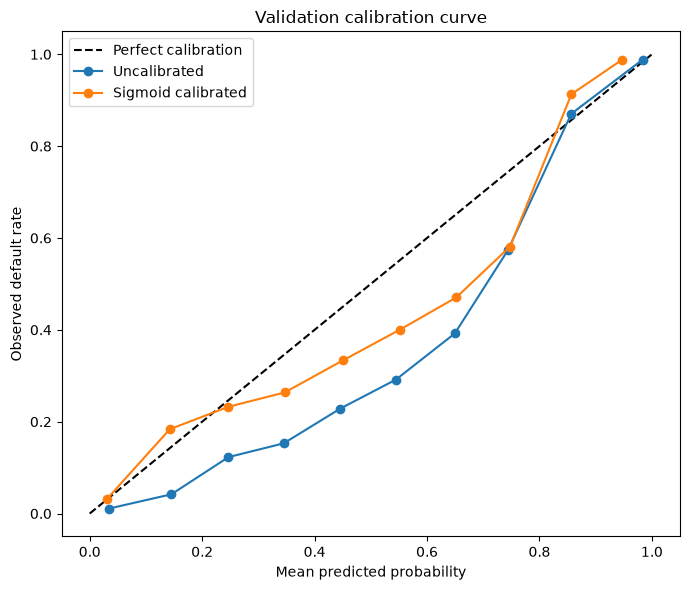

In [42]:
from sklearn.metrics import brier_score_loss

print("Uncalibrated Brier score:", round(brier_score_loss(y_val, uncalibrated), 4))
print("Calibrated Brier score:  ", round(brier_score_loss(y_val, calibrated), 4))

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.plot(predicted_uncal, actual_uncal, "o-", label="Uncalibrated")
plt.plot(predicted_cal, actual_cal, "o-", label="Sigmoid calibrated")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("Validation calibration curve")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Understanding the model with SHAP

SHAP helps explain which features are driving the model's output. These explanations describe the fitted model; they do not prove that a feature causes default. I use validation examples here so that the final test set remains reserved for final evaluation.

In [43]:
# SHAP is optional; install it in the environment if it is unavailable.

! pip install SHAP
import shap

In [44]:
xgb_classifier = best_model.named_steps["classifier"]

In [45]:
X_val_transformed = best_model.named_steps["preprocessor"].transform(X_val)

In [46]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

In [47]:
# Keep the transformed columns aligned with their feature names.
if hasattr(X_val_transformed, "toarray"):
    X_val_array = X_val_transformed.toarray()
else:
    X_val_array = X_val_transformed

X_val_df = pd.DataFrame(
    X_val_array,
    columns=feature_names,
    index=X_val.index
)

In [48]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [49]:
shap_values = explainer.shap_values(X_val_df)
shap_values

array([[ 1.6995901e-01,  6.3203698e-01, -1.2864828e-01, ...,
        -6.8564848e-03,  2.3810001e-02,  5.2603842e-03],
       [-1.5696093e-01, -4.9025664e-01, -1.0168268e-01, ...,
        -7.5705708e-03,  4.1915788e-03, -2.0545637e-03],
       [ 2.3694280e-01,  3.5416570e-01, -8.9591719e-02, ...,
        -6.7684865e-03, -1.7058402e-02, -2.0545637e-03],
       ...,
       [-9.1302469e-02,  4.0949830e-01,  4.3538522e-02, ...,
        -8.1793955e-03, -3.0538585e-02,  4.7915373e-03],
       [ 9.3657255e-02, -5.1232297e-03, -7.4030749e-02, ...,
        -7.1239099e-03, -9.5619546e-04, -2.0545637e-03],
       [-9.6164107e-02, -6.3647193e-01, -1.6354588e-01, ...,
        -9.6136322e-03, -3.7609093e-04, -4.9199965e-03]],
      shape=(6482, 26), dtype=float32)

### Global explanation
- This shows which features matter most overall.
- It also shows if a feature increases or decreases risk.

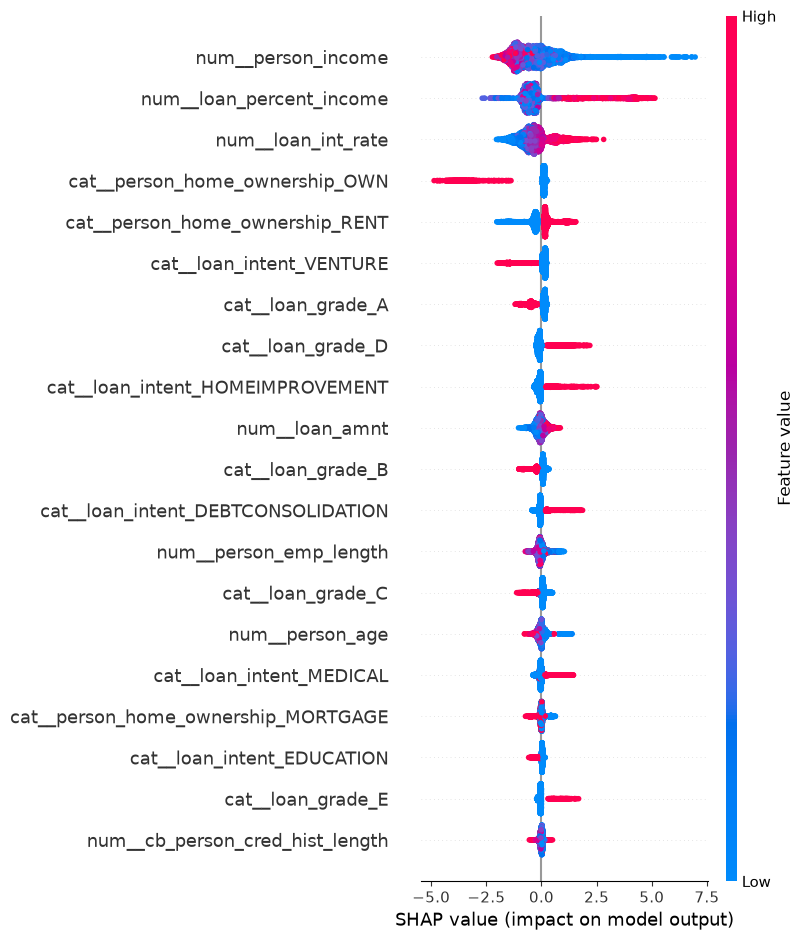

In [50]:
shap.summary_plot(shap_values, X_val_df)

### Local explanation
- This shows why one specific applicant got their score.
- It breaks the score down feature by feature.

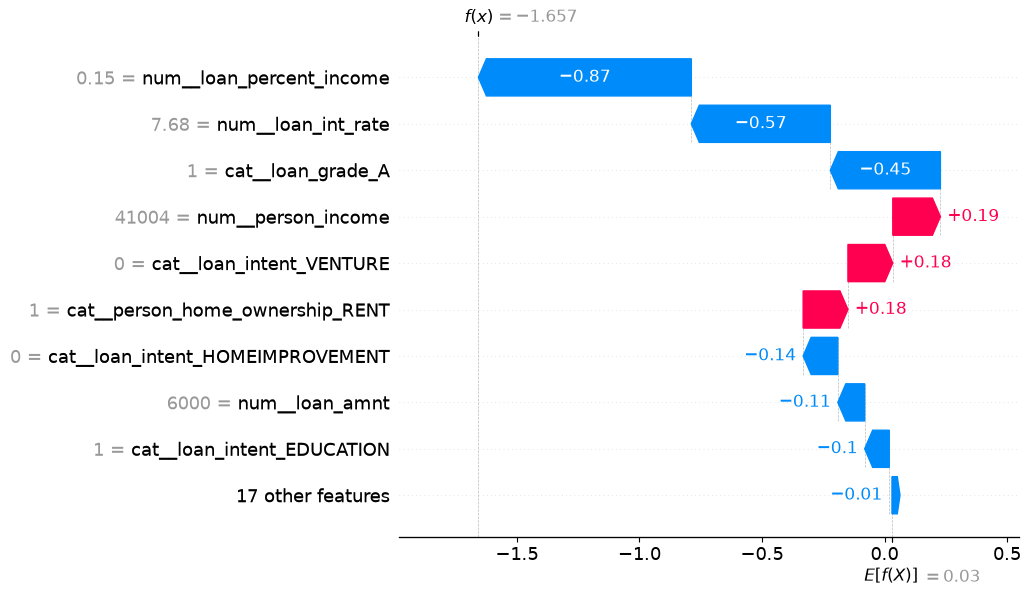

In [51]:
# Explain one validation applicant. This is an example, not a representative case.
row_index = 5

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[row_index],
        base_values=explainer.expected_value,
        data=X_val_df.iloc[row_index],
        feature_names=feature_names
    )
)

### Looking at individual feature effects

A dependence plot shows how the SHAP contribution of one feature changes across its values. I use the features with the largest average absolute SHAP values, rather than selecting examples by looking at the test set.

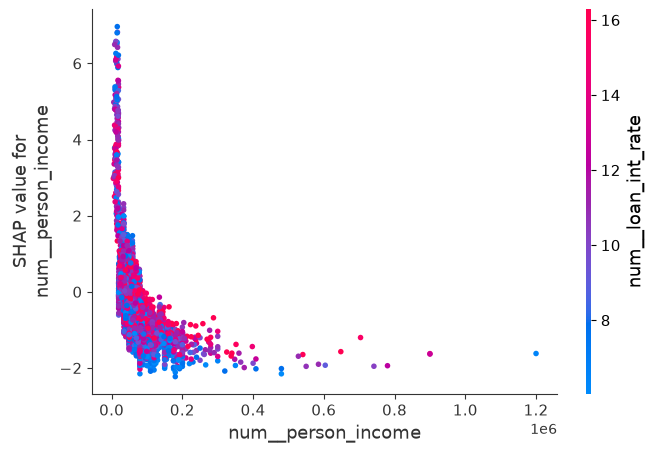

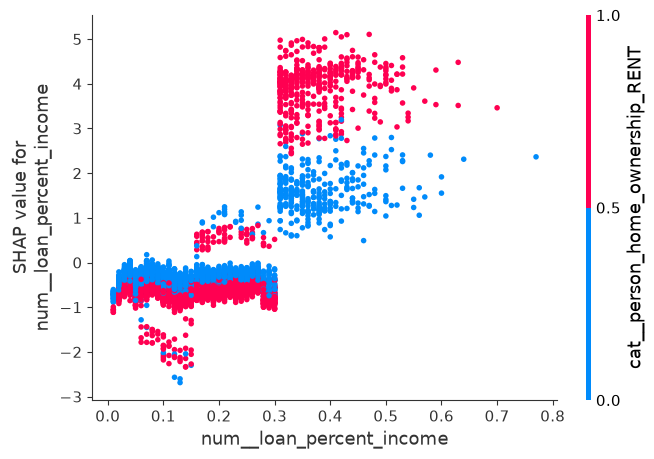

In [52]:
# The first two features are selected from the global SHAP importance ranking.
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_feature_indices = np.argsort(mean_abs_shap)[-2:][::-1]

for feature_index in top_feature_indices:
    shap.dependence_plot(
        feature_names[feature_index],
        shap_values,
        X_val_df,
        feature_names=feature_names
    )

## 15. Reviewing false positives and false negatives

A false positive is a non-default applicant flagged as a default. A false negative is a default applicant the model misses. Both matter, but their business costs may be different.

Final calibrated XGBoost (test) — threshold: 0.633


,Threshold,ROC-AUC,PR-AUC (AP),Accuracy,Precision,Recall,F1,Specificity,Balanced accuracy,MCC,Brier score
Model,,,,,,,,,,,
Final calibrated XGBoost (test),0.633325,0.951423,0.909007,0.937211,0.955816,0.747532,0.838939,0.990324,0.868928,0.809995,0.05284


              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5064
           1       0.96      0.75      0.84      1418

    accuracy                           0.94      6482
   macro avg       0.94      0.87      0.90      6482
weighted avg       0.94      0.94      0.93      6482



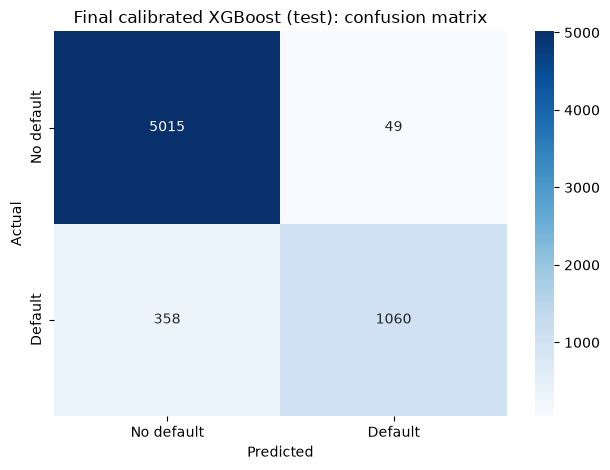

In [53]:
test_metrics = evaluate_model(
    "Final calibrated XGBoost (test)",
    calibrated_model,
    X_test,
    y_test,
    best_threshold
)

y_pred_prob = calibrated_model.predict_proba(X_test)[:, 1]
y_pred = (y_pred_prob >= best_threshold).astype(int)

In [54]:
#Create a dataframe to easily compare the actual and predicted values

result_df = X_test.copy()

result_df['actual'] = y_test

result_df['predicted'] = y_pred

In [55]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [56]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 49
False Negative : 358


In [57]:
#False Negative > False Positive

## 16. Save the model

I save the fitted probability model and the threshold selected on validation data. The preprocessing steps are part of the saved pipeline, so new data should be passed in using the same input columns.

In [61]:
import joblib
from pathlib import Path

# Get the project root directory
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Create models directory
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save model
model_path = model_dir / "credit_risk_model.joblib"

joblib.dump(
    {
        "model": calibrated_model,
        "threshold": best_threshold,
        "risk_band_cutoffs": {
            "low_max": 0.10,
            "medium_max": 0.30
        },
        "features": list(X_train.columns)
    },
    model_path
)

print("Model saved successfully!")
print(f"Location: {model_path}")

Model saved successfully!
Location: d:\GOURAB DAS\CODE\Git\FinSight AI\models\credit_risk_model.joblib


## Wrap-up

This notebook builds a baseline and an XGBoost model, compares them using validation data, checks probability calibration, and evaluates the chosen approach on a held-out test set. The next steps are to assess business costs, review feature availability at the intended prediction point, and test the model on newer data.